In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df_viz = df.copy()
df_viz["Age"] = df_viz["Age"].fillna(df_viz["Age"].median())
df_viz["Embarked"] = df_viz["Embarked"].fillna(df_viz["Embarked"].mode()[0])

print("Dataset shape:", df_viz.shape)
df_viz.head()

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


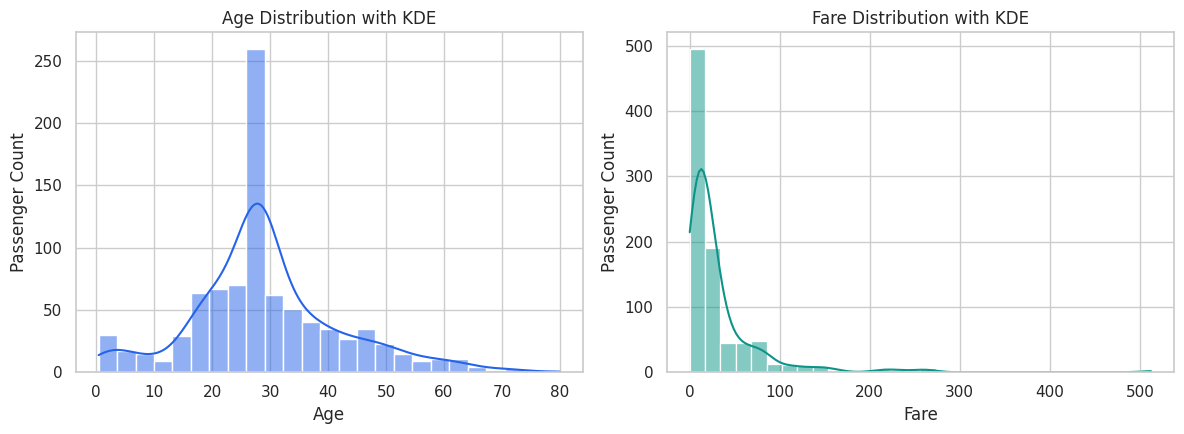

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(data=df_viz, x="Age", bins=25, kde=True, color="#2563EB", ax=axes[0])
axes[0].set_title("Age Distribution with KDE")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Passenger Count")

sns.histplot(data=df_viz, x="Fare", bins=30, kde=True, color="#0D9488", ax=axes[1])
axes[1].set_title("Fare Distribution with KDE")
axes[1].set_xlabel("Fare")
axes[1].set_ylabel("Passenger Count")

plt.tight_layout()
plt.show()

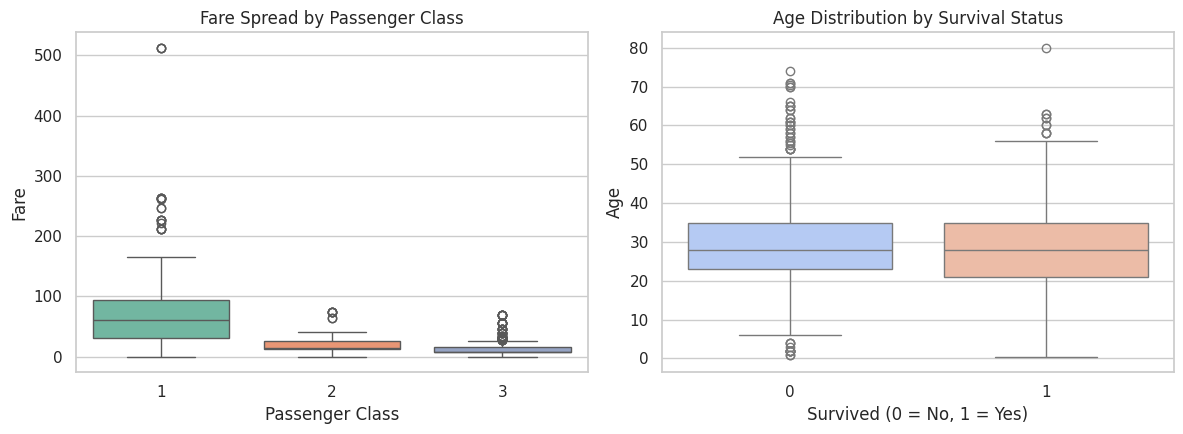

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df_viz, x="Pclass", y="Fare", hue="Pclass", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Fare Spread by Passenger Class")
axes[0].set_xlabel("Passenger Class")
axes[0].set_ylabel("Fare")

sns.boxplot(data=df_viz, x="Survived", y="Age", hue="Survived", palette="coolwarm", legend=False, ax=axes[1])
axes[1].set_title("Age Distribution by Survival Status")
axes[1].set_xlabel("Survived (0 = No, 1 = Yes)")
axes[1].set_ylabel("Age")

plt.tight_layout()
plt.show()

Correlation Matrix:
           Survived  Pclass   Age  SibSp  Parch  Fare
Survived      1.00   -0.34 -0.06  -0.04   0.08  0.26
Pclass       -0.34    1.00 -0.34   0.08   0.02 -0.55
Age          -0.06   -0.34  1.00  -0.23  -0.17  0.10
SibSp        -0.04    0.08 -0.23   1.00   0.41  0.16
Parch         0.08    0.02 -0.17   0.41   1.00  0.22
Fare          0.26   -0.55  0.10   0.16   0.22  1.00


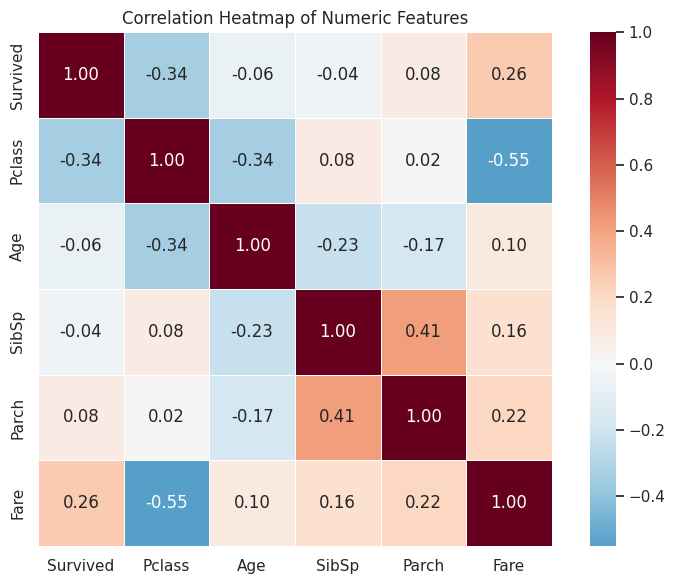

In [4]:
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr_matrix = df_viz[numeric_cols].corr()

print("Correlation Matrix:\n", corr_matrix.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    square=True
)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

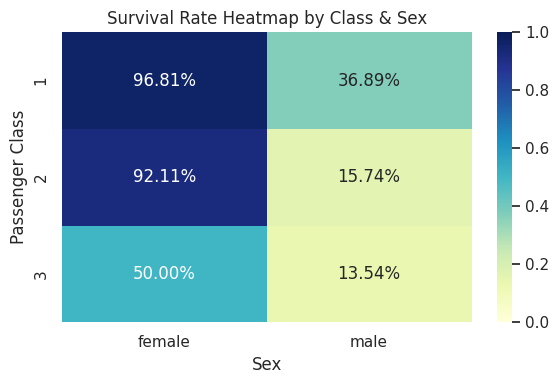

In [5]:
survival_pivot = df_viz.pivot_table(
    values="Survived", index="Pclass", columns="Sex", aggfunc="mean"
)

plt.figure(figsize=(6, 4))
sns.heatmap(survival_pivot, annot=True, fmt=".2%", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Survival Rate Heatmap by Class & Sex")
plt.xlabel("Sex")
plt.ylabel("Passenger Class")
plt.tight_layout()
plt.show()